In [9]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

# Time available (0 to 12 hours)
time = ctrl.Antecedent(np.arange(0, 13, 1), 'time')

# History interest (0 to 10 scale)
interest_history = ctrl.Antecedent(np.arange(0, 11, 1), 'interest_history')

# Budget per tour (0 to 200 CHF)[cite: 12]
budget = ctrl.Antecedent(np.arange(0, 201, 1), 'budget')

# Output: Suitability Score (0 to 100) defuzzified via centroid[cite: 11, 12]
suitability = ctrl.Consequent(np.arange(0, 101, 1), 'suitability')


In [10]:
time.automf(3, names=['few_hours', 'half_day', 'full_day'])
interest_history.automf(3, names=['low', 'moderate', 'high'])
suitability.automf(3, names=['low', 'moderate', 'high'])

# Custom membership for Budget (Low, Moderate, High) to match the prototype graph[cite: 12]
# Using triangular functions where 60 CHF overlaps Low and Moderate[cite: 12]
budget['low'] = fuzz.trimf(budget.universe, [0, 0, 80])
budget['moderate'] = fuzz.trimf(budget.universe, [40, 100, 160])
budget['high'] = fuzz.trimf(budget.universe, [120, 200, 200])


Running Fuzzy Bern Guide simulation for Alex...
Calculated Guide Suitability Score: 56.3/100


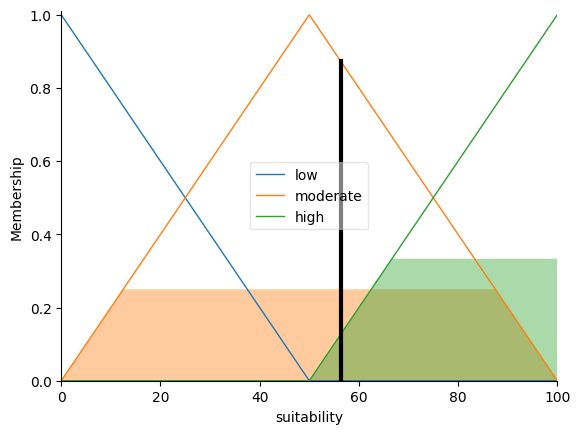

In [11]:
# Core Example Rule[cite: 12]:
rule1 = ctrl.Rule(
    time['few_hours'] & interest_history['high'] & budget['moderate'], 
    suitability['high']
)

# Additional rules to support the logic[cite: 11]
rule2 = ctrl.Rule(budget['low'] & interest_history['low'], suitability['low'])
rule3 = ctrl.Rule(time['full_day'] & budget['high'], suitability['high'])
rule4 = ctrl.Rule(budget['low'] & interest_history['high'], suitability['moderate'])

# ---------------------------------------------------------
# 4. Build Control System and Simulate
# ---------------------------------------------------------
guide_ctrl = ctrl.ControlSystem([rule1, rule2, rule3, rule4])
guide_sim = ctrl.ControlSystemSimulation(guide_ctrl)

# ---------------------------------------------------------
# 5. Execution for Zeeshan (Testing the Day-Tripper Profile)
# ---------------------------------------------------------
# Setting inputs based on a moderate budget overlapping membership[cite: 12]
print("Running Fuzzy Bern Guide simulation for Alex...")
guide_sim.input['time'] = 3                # 3 hours available
guide_sim.input['interest_history'] = 9    # High interest in history
guide_sim.input['budget'] = 60             # 60 CHF budget[cite: 12]

# Compute the result
guide_sim.compute()
final_score = guide_sim.output['suitability']

print(f"Calculated Guide Suitability Score: {final_score:.1f}/100")

# Visualize the defuzzification[cite: 11]
suitability.view(sim=guide_sim)
plt.show()